=== CAPSTONE PHASE III: MODEL EVALUATION RESULTS ===

Random Forest:
 - Root Mean Squared Error (RMSE): 8.05
 - Mean Absolute Error (MAE): 6.33
 - R-squared (R2 Score): 0.9914

XGBoost Regressor:
 - Root Mean Squared Error (RMSE): 8.04
 - Mean Absolute Error (MAE): 6.36
 - R-squared (R2 Score): 0.9914


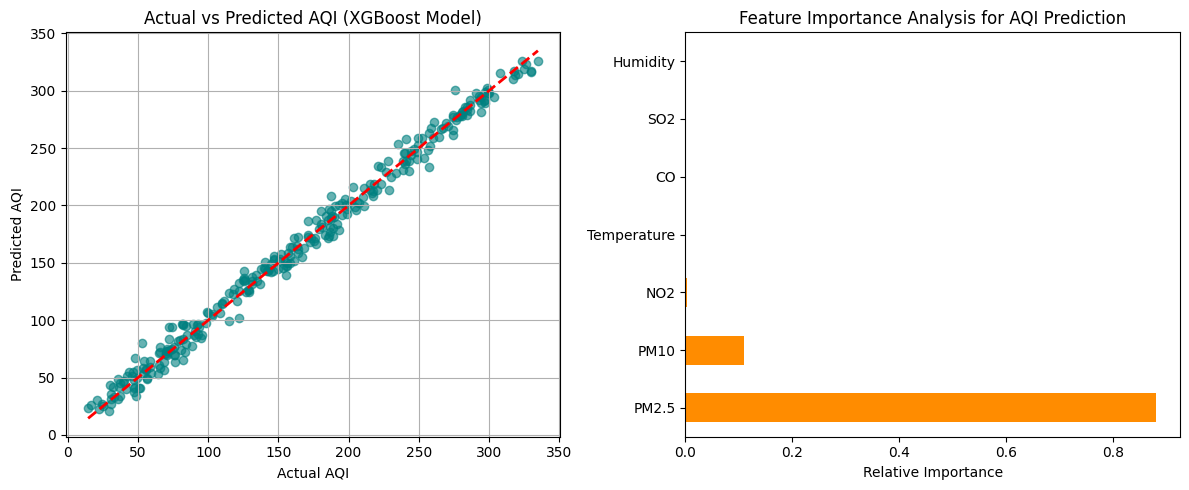

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

# 1. Dataset Generation (Simulating CPCB Multi-Sensor Air Quality Data)
np.random.seed(42)
n_samples = 1500

pm25 = np.random.uniform(10, 350, n_samples)
pm10 = pm25 * np.random.uniform(1.2, 2.0, n_samples)
no2 = np.random.uniform(5, 120, n_samples)
so2 = np.random.uniform(2, 50, n_samples)
co = np.random.uniform(0.1, 5.0, n_samples)
temp = np.random.uniform(15, 42, n_samples)
humidity = np.random.uniform(20, 90, n_samples)

# Formula for target variable (AQI)x
aqi = 0.45 * pm25 + 0.25 * pm10 + 0.15 * no2 + 0.1 * temp + np.random.normal(0, 8, n_samples)

df = pd.DataFrame({
    'PM2.5': pm25, 'PM10': pm10, 'NO2': no2, 'SO2': so2,
    'CO': co, 'Temperature': temp, 'Humidity': humidity, 'AQI': aqi
})

# 2. Data Preprocessing & Train-Test Split (80-20 Split)
X = df.drop('AQI', axis=1)
y = df['AQI']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Model Training & Comparison (Random Forest vs XGBoost)
models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost Regressor": xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
}

print("=== CAPSTONE PHASE III: MODEL EVALUATION RESULTS ===")
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    print(f"\n{name}:")
    print(f" - Root Mean Squared Error (RMSE): {rmse:.2f}")
    print(f" - Mean Absolute Error (MAE): {mae:.2f}")
    print(f" - R-squared (R2 Score): {r2:.4f}")

# 4. Visualization Plots for Form Evidence Submission
plt.figure(figsize=(12, 5))

# Plot 1: Actual vs Predicted
plt.subplot(1, 2, 1)
rf_preds = models["XGBoost Regressor"].predict(X_test)
plt.scatter(y_test, rf_preds, alpha=0.6, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title("Actual vs Predicted AQI (XGBoost Model)")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.grid(True)

# Plot 2: Feature Importance
plt.subplot(1, 2, 2)
feat_importances = pd.Series(models['XGBoost Regressor'].feature_importances_, index=X.columns)
feat_importances.nlargest(7).plot(kind='barh', color='darkorange')
plt.title("Feature Importance Analysis for AQI Prediction")
plt.xlabel("Relative Importance")
plt.tight_layout()

# Save image locally for upload
plt.savefig("AQI_Phase3_Experimental_Results.png", dpi=300)
plt.show()